# 01 — Exploratory Data Analysis & Data Quality Checks

**Project:** Explainable and Efficient Machine Learning for Short-Term Solar Power Forecasting
**Scope of this notebook:** understand the raw data before any modeling. No feature engineering
or model training happens here — only loading, validation, and visual exploration. The goal is
to surface data-quality issues (bad timestamps, gaps, unit/scale mismatches, bad sensors,
underperforming inverters) so preprocessing decisions later are justified by evidence, not guesswork.

**Data:** Kaggle "Solar Power Generation Data" — two solar plants in India, ~34 days of
15-minute-interval readings. Each plant has two files:
- `Generation` — inverter-level (`SOURCE_KEY`) `DC_POWER`, `AC_POWER`, `DAILY_YIELD`, `TOTAL_YIELD`
- `Weather Sensor` — plant-level `AMBIENT_TEMPERATURE`, `MODULE_TEMPERATURE`, `IRRADIATION`


In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

RAW_DIR = Path("..") / "data" / "raw"
FIG_DIR = Path("..") / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PLANTS = ["Plant_1", "Plant_2"]

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved -> {path}")


## 1. Load the raw CSVs

Loaded as plain strings for `DATE_TIME` at this stage — parsing is deliberately deferred to
Section 2, since the raw layout already shows the two plants' generation files are not
guaranteed to share a date format, and assuming they do without checking is exactly the kind
of silent bug that breaks a merge later.


In [2]:
raw = {}
for plant in PLANTS:
    raw[f"{plant}_gen"] = pd.read_csv(RAW_DIR / f"{plant}_Generation_Data.csv")
    raw[f"{plant}_weather"] = pd.read_csv(RAW_DIR / f"{plant}_Weather_Sensor_Data.csv")

for name, df in raw.items():
    print(f"{name:20s} shape={df.shape}")


Plant_1_gen          shape=(68778, 7)
Plant_1_weather      shape=(3182, 6)
Plant_2_gen          shape=(67698, 7)
Plant_2_weather      shape=(3259, 6)


In [3]:
for name, df in raw.items():
    print(f"\n--- {name} ---")
    print(df.dtypes)



--- Plant_1_gen ---
DATE_TIME          str
PLANT_ID         int64
SOURCE_KEY         str
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object

--- Plant_1_weather ---
DATE_TIME                  str
PLANT_ID                 int64
SOURCE_KEY                 str
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object

--- Plant_2_gen ---
DATE_TIME          str
PLANT_ID         int64
SOURCE_KEY         str
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object

--- Plant_2_weather ---
DATE_TIME                  str
PLANT_ID                 int64
SOURCE_KEY                 str
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object


**Decision:** check missing values and duplicate rows before touching anything else.
Generation data is keyed by `(DATE_TIME, SOURCE_KEY)` — a duplicate on that key would silently
double-count power if not caught now.


In [4]:
summary_rows = []
for name, df in raw.items():
    n_missing = df.isna().sum().sum()
    if "gen" in name:
        dup_key = df.duplicated(subset=["DATE_TIME", "SOURCE_KEY"]).sum()
    else:
        dup_key = df.duplicated(subset=["DATE_TIME", "SOURCE_KEY"]).sum()
    dup_full = df.duplicated().sum()
    summary_rows.append({
        "file": name,
        "rows": len(df),
        "missing_values": n_missing,
        "duplicate_rows_full": dup_full,
        "duplicate_rows_on_key": dup_key,
    })

quality_summary = pd.DataFrame(summary_rows)
quality_summary


,file,rows,missing_values,duplicate_rows_full,duplicate_rows_on_key
0,Plant_1_gen,68778,0,0,0
1,Plant_1_weather,3182,0,0,0
2,Plant_2_gen,67698,0,0,0
3,Plant_2_weather,3259,0,0,0


## 2. Parse `DATE_TIME` — verify the format per file, don't assume

Rather than hardcode a format from eyeballing the CSV, detect it programmatically from the
first value of each file: if the first token before the first separator is 4 digits it's
`YYYY-MM-DD...` (ISO), otherwise it's `DD-MM-YYYY...`. This makes the assumption explicit and
checkable, and the notebook will raise instead of silently mis-parsing if a file doesn't match
either pattern.


In [5]:
def detect_and_parse(series: pd.Series) -> pd.Series:
    sample = str(series.iloc[0])
    first_token = re.split(r"[-\s]", sample)[0]
    if len(first_token) == 4 and first_token.isdigit():
        fmt = "%Y-%m-%d %H:%M:%S"
    else:
        fmt = "%d-%m-%Y %H:%M"
    parsed = pd.to_datetime(series, format=fmt, errors="raise")
    return parsed, fmt

for name, df in raw.items():
    parsed, fmt = detect_and_parse(df["DATE_TIME"])
    df["DATE_TIME"] = parsed
    n_nat = df["DATE_TIME"].isna().sum()
    print(f"{name:20s} format='{fmt}'  range=[{parsed.min()} .. {parsed.max()}]  NaT={n_nat}")


Plant_1_gen          format='%d-%m-%Y %H:%M'  range=[2020-05-15 00:00:00 .. 2020-06-17 23:45:00]  NaT=0
Plant_1_weather      format='%Y-%m-%d %H:%M:%S'  range=[2020-05-15 00:00:00 .. 2020-06-17 23:45:00]  NaT=0
Plant_2_gen          format='%Y-%m-%d %H:%M:%S'  range=[2020-05-15 00:00:00 .. 2020-06-17 23:45:00]  NaT=0
Plant_2_weather      format='%Y-%m-%d %H:%M:%S'  range=[2020-05-15 00:00:00 .. 2020-06-17 23:45:00]  NaT=0


**Finding so far:** `Plant_1_Generation_Data.csv` is the odd one out — `DD-MM-YYYY HH:MM`
with no seconds — while the other three files are ISO `YYYY-MM-DD HH:MM:SS`. This matches the
brief's warning that the two plants may not share a date format, and confirms it's a per-file
issue rather than a per-plant one (Plant 1's own weather file uses ISO format).


## 3. Timestamp gaps and generation/weather alignment

Readings are nominally every 15 minutes. For each plant:
- build the expected complete 15-min grid spanning that plant's observed range,
- compare it against the *unique* timestamps actually present (generation and weather separately,
  since they're recorded by different sensors and could drop readings independently),
- check whether the generation and weather timestamp sets actually line up — this matters
  because any merge in preprocessing will inner-join (or need to) on `DATE_TIME`.


In [6]:
gap_rows = []
alignment_rows = []

for plant in PLANTS:
    gen = raw[f"{plant}_gen"]
    wx = raw[f"{plant}_weather"]

    gen_ts = pd.Index(sorted(gen["DATE_TIME"].unique()))
    wx_ts = pd.Index(sorted(wx["DATE_TIME"].unique()))

    full_start = min(gen_ts.min(), wx_ts.min())
    full_end = max(gen_ts.max(), wx_ts.max())
    full_grid = pd.date_range(full_start, full_end, freq="15min")

    gap_rows.append({
        "plant": plant, "series": "generation",
        "expected_steps": len(full_grid), "observed_steps": len(gen_ts),
        "missing_steps": len(full_grid) - len(gen_ts),
    })
    gap_rows.append({
        "plant": plant, "series": "weather",
        "expected_steps": len(full_grid), "observed_steps": len(wx_ts),
        "missing_steps": len(full_grid) - len(wx_ts),
    })

    only_in_gen = gen_ts.difference(wx_ts)
    only_in_wx = wx_ts.difference(gen_ts)
    alignment_rows.append({
        "plant": plant,
        "timestamps_only_in_generation": len(only_in_gen),
        "timestamps_only_in_weather": len(only_in_wx),
        "common_timestamps": len(gen_ts.intersection(wx_ts)),
    })

gap_summary = pd.DataFrame(gap_rows)
alignment_summary = pd.DataFrame(alignment_rows)
display(gap_summary)
display(alignment_summary)


,plant,series,expected_steps,observed_steps,missing_steps
0,Plant_1,generation,3264,3158,106
1,Plant_1,weather,3264,3182,82
2,Plant_2,generation,3264,3259,5
3,Plant_2,weather,3264,3259,5


,plant,timestamps_only_in_generation,timestamps_only_in_weather,common_timestamps
0,Plant_1,1,25,3157
1,Plant_2,0,0,3259


**Decision implied by this check:** if `missing_steps` is small relative to total steps,
a straightforward resample/reindex-and-interpolate (or forward-fill for yield counters) in
preprocessing is defensible. If `timestamps_only_in_*` is large, an inner join on `DATE_TIME`
would silently drop real data and should instead be an outer join with explicit handling of
the gaps.


## 4. DC_POWER vs AC_POWER ratio — unit/scale sanity check

A grid-tied inverter's AC output is close to, but slightly less than, its DC input (typical
inverter efficiency is roughly 95-99%), so `AC_POWER / DC_POWER` should sit just under 1 whenever
DC_POWER is non-trivial. A ratio far below that (e.g. ~0.1) for an entire plant points at a
unit or scaling mismatch between the two columns, not real inverter inefficiency, and needs to
be corrected (or at least documented) before it's used as a model feature.


In [7]:
ratio_rows = []
for plant in PLANTS:
    gen = raw[f"{plant}_gen"]
    active = gen[gen["DC_POWER"] > 10]  # ignore near-zero night-time noise
    ratio = active["AC_POWER"] / active["DC_POWER"]
    ratio_rows.append({
        "plant": plant,
        "n_active_rows": len(active),
        "mean_ac_dc_ratio": ratio.mean(),
        "median_ac_dc_ratio": ratio.median(),
        "mean_dc_power": active["DC_POWER"].mean(),
        "mean_ac_power": active["AC_POWER"].mean(),
    })

ratio_summary = pd.DataFrame(ratio_rows)
ratio_summary["flag_scale_issue"] = ratio_summary["mean_ac_dc_ratio"] < 0.5
ratio_summary


,plant,n_active_rows,mean_ac_dc_ratio,median_ac_dc_ratio,mean_dc_power,mean_ac_power,flag_scale_issue
0,Plant_1,36818,0.097719,0.097845,5879.558819,574.991842,True
1,Plant_2,31178,0.977137,0.978555,535.566416,523.792550,False


## 5. Visual exploration

Each plot below is saved to `results/figures/` for reuse in the report/viva slides.


### 5.1 Daily generation curves (diurnal profile)

Plant-level `AC_POWER` (summed across inverters), plotted against time-of-day with one line
per calendar day. This is the standard way to see the shape of the solar day and spot days
that are abnormally low (cloud cover) or truncated (sensor dropout) at a glance.


saved -> ..\results\figures\01_daily_generation_curves.png


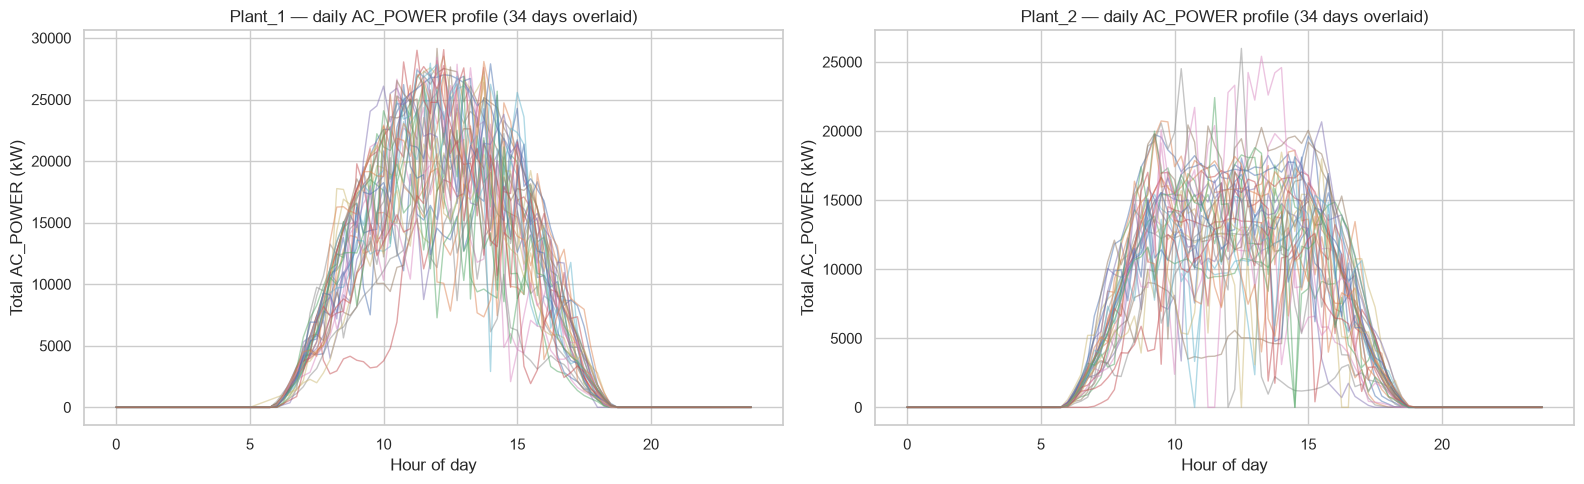

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=False)
for ax, plant in zip(axes, PLANTS):
    gen = raw[f"{plant}_gen"].copy()
    plant_total = gen.groupby("DATE_TIME", as_index=False)["AC_POWER"].sum()
    plant_total["date"] = plant_total["DATE_TIME"].dt.date
    plant_total["time_of_day"] = plant_total["DATE_TIME"].dt.hour + plant_total["DATE_TIME"].dt.minute / 60

    for day, grp in plant_total.groupby("date"):
        ax.plot(grp["time_of_day"], grp["AC_POWER"], alpha=0.5, linewidth=1)
    ax.set_title(f"{plant} — daily AC_POWER profile ({plant_total['date'].nunique()} days overlaid)")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Total AC_POWER (kW)")

fig.tight_layout()
save_fig(fig, "01_daily_generation_curves.png")
plt.show()


### 5.2 Irradiation vs AC_POWER

Generation and weather are recorded by different sensors, so they're merged on `DATE_TIME`
per plant (inner join — Section 3 showed how much this does or doesn't throw away) before
plotting. Irradiation should be close to linearly related to output; outliers off that trend
are candidates for sensor or inverter faults.


saved -> ..\results\figures\02_irradiation_vs_ac_power.png


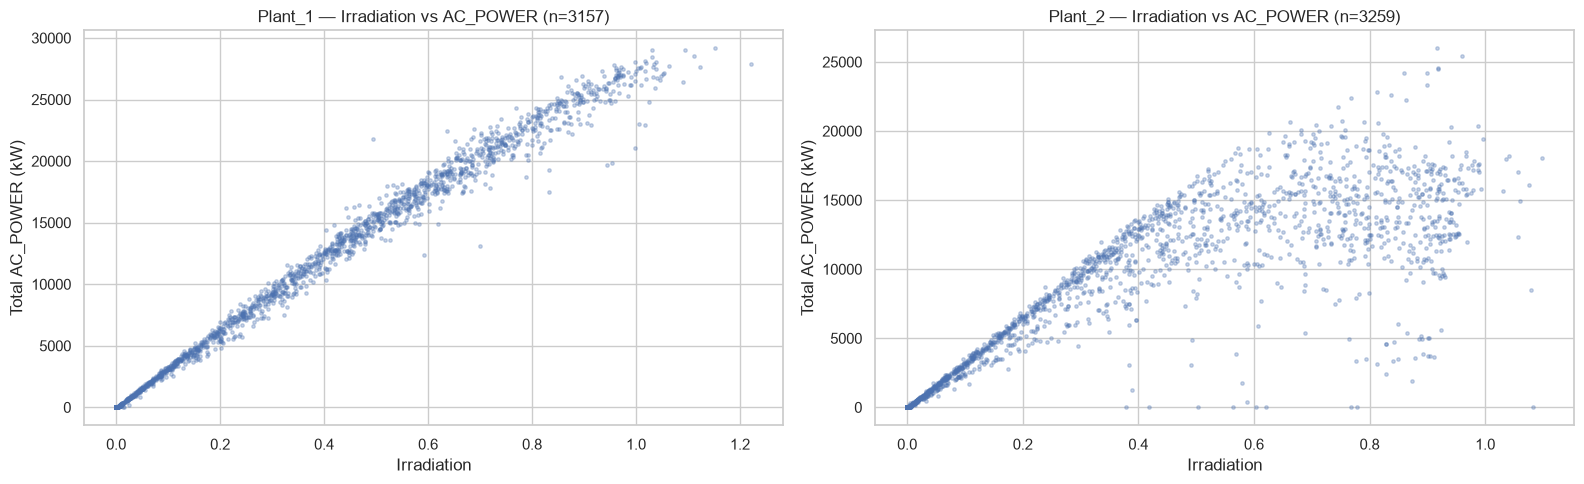

In [9]:
merged = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, plant in zip(axes, PLANTS):
    gen = raw[f"{plant}_gen"].groupby("DATE_TIME", as_index=False)[["DC_POWER", "AC_POWER"]].sum()
    wx = raw[f"{plant}_weather"][["DATE_TIME", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]]
    m = gen.merge(wx, on="DATE_TIME", how="inner")
    merged[plant] = m

    ax.scatter(m["IRRADIATION"], m["AC_POWER"], s=6, alpha=0.3)
    ax.set_title(f"{plant} — Irradiation vs AC_POWER (n={len(m)})")
    ax.set_xlabel("Irradiation")
    ax.set_ylabel("Total AC_POWER (kW)")

fig.tight_layout()
save_fig(fig, "02_irradiation_vs_ac_power.png")
plt.show()


### 5.3 Module vs ambient temperature

Module (panel surface) temperature should track ambient temperature but run higher whenever
there's irradiation heating the panel — points far below the `y = x` reference line, or that
don't rise with irradiation, suggest a sensor issue.


saved -> ..\results\figures\03_module_vs_ambient_temperature.png


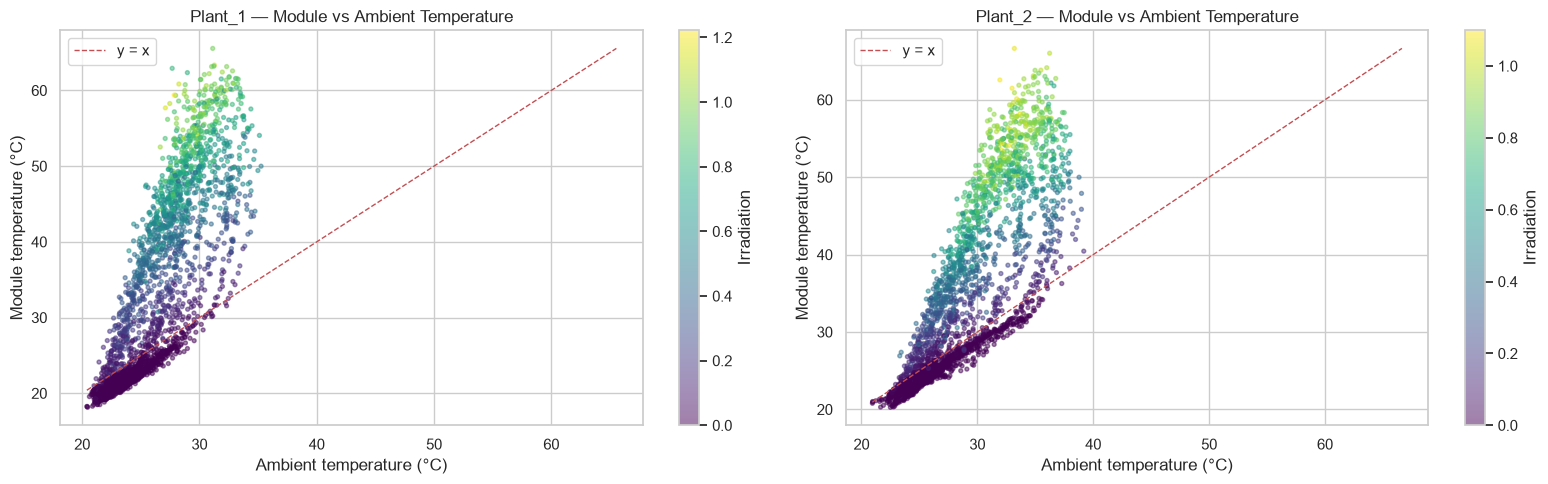

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, plant in zip(axes, PLANTS):
    m = merged[plant]
    sc = ax.scatter(m["AMBIENT_TEMPERATURE"], m["MODULE_TEMPERATURE"],
                     c=m["IRRADIATION"], cmap="viridis", s=8, alpha=0.5)
    lims = [m["AMBIENT_TEMPERATURE"].min(), m["MODULE_TEMPERATURE"].max()]
    ax.plot(lims, lims, "r--", linewidth=1, label="y = x")
    ax.set_title(f"{plant} — Module vs Ambient Temperature")
    ax.set_xlabel("Ambient temperature (°C)")
    ax.set_ylabel("Module temperature (°C)")
    ax.legend(loc="upper left")
    fig.colorbar(sc, ax=ax, label="Irradiation")

fig.tight_layout()
save_fig(fig, "03_module_vs_ambient_temperature.png")
plt.show()


### 5.4 Correlation heatmap

Correlations among the plant-level numeric signals (summed DC/AC power, irradiation, ambient
and module temperature), computed per plant since the DC/AC scale issue found in Section 4
could otherwise distort a combined view.


saved -> ..\results\figures\04_correlation_heatmap.png


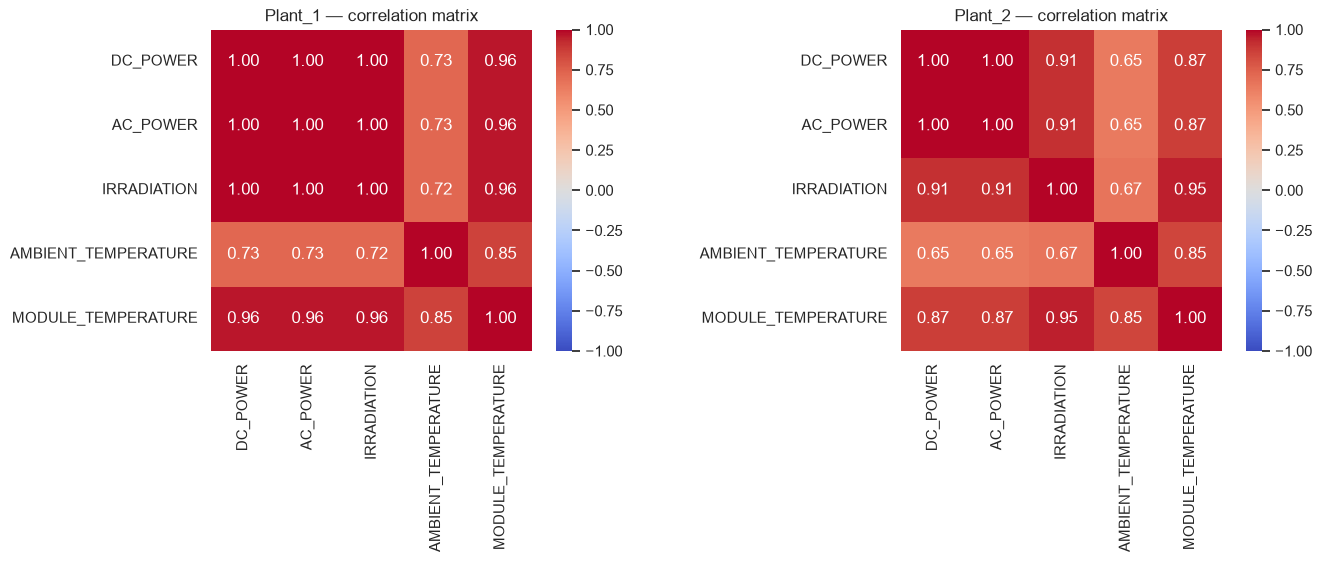

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, plant in zip(axes, PLANTS):
    m = merged[plant]
    corr_cols = ["DC_POWER", "AC_POWER", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]
    corr = m[corr_cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, square=True)
    ax.set_title(f"{plant} — correlation matrix")

fig.tight_layout()
save_fig(fig, "04_correlation_heatmap.png")
plt.show()


### 5.5 Per-inverter output — spotting underperformers

`AC_POWER` distribution per inverter (`SOURCE_KEY`), restricted to daylight rows (`IRRADIATION
> 0` via the merged timestamps, approximated here with `DC_POWER > 10` on the generation data
directly to keep all inverters without needing the merge) and ordered by median output. An
inverter with a visibly lower median/box than its peers under the same conditions is a
candidate for the residual-based underperformance flagging planned later in the project.


saved -> ..\results\figures\05_per_inverter_output.png


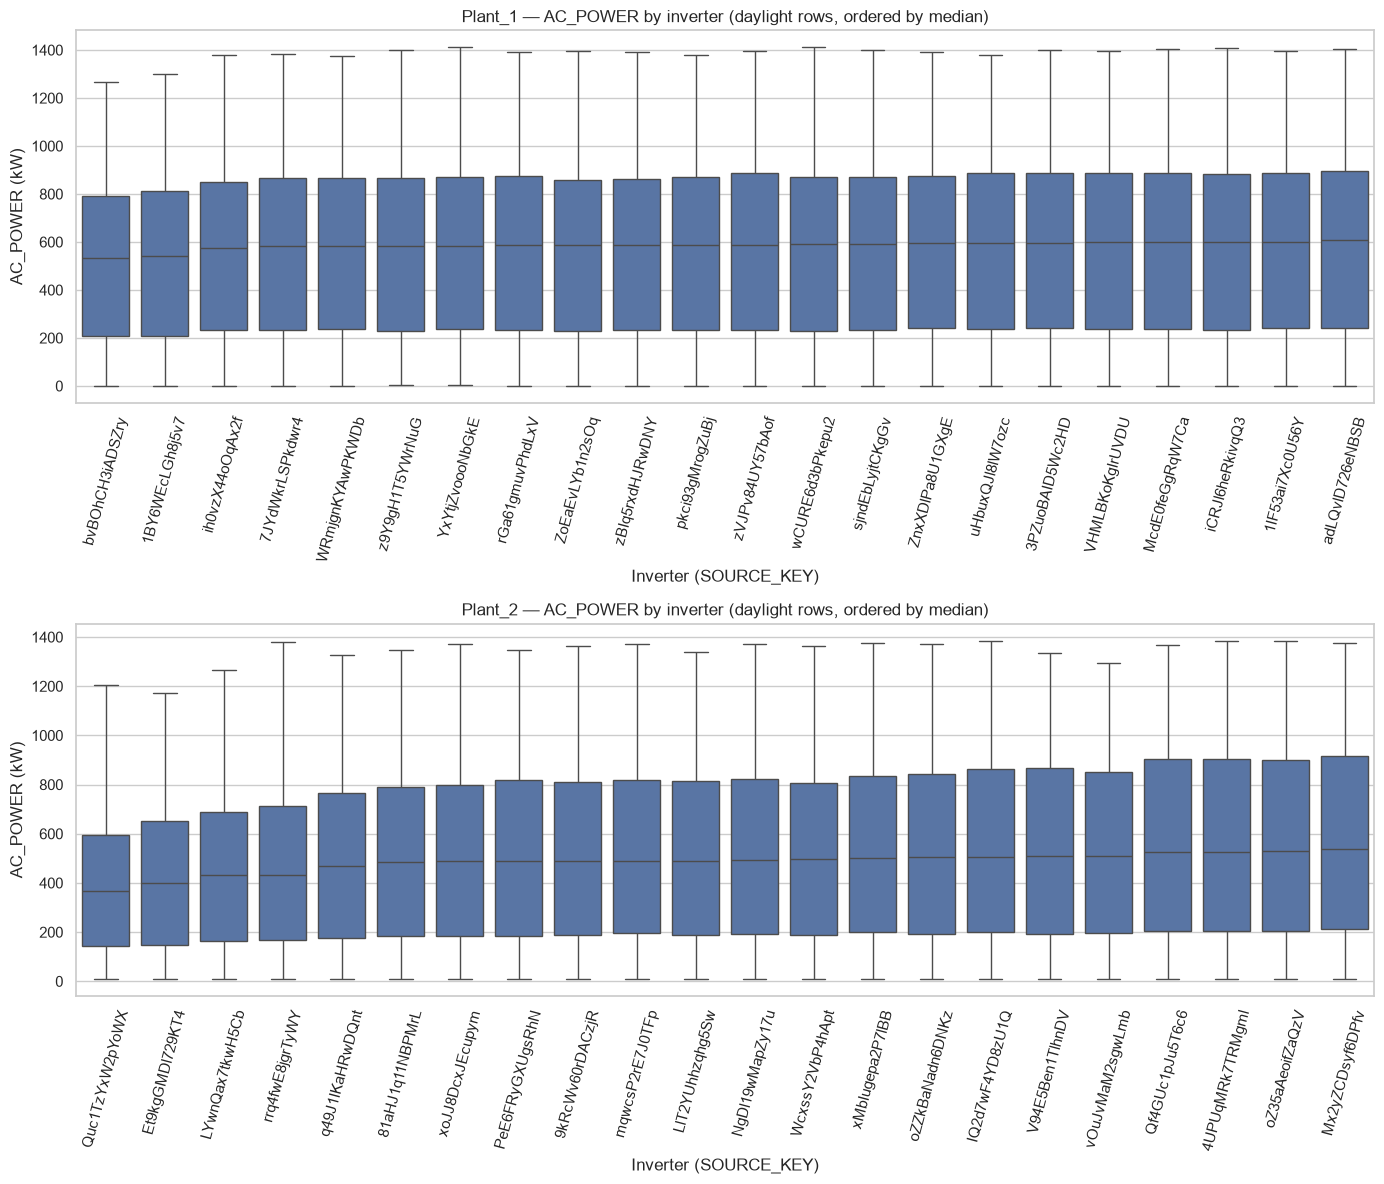

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12))
for ax, plant in zip(axes, PLANTS):
    gen = raw[f"{plant}_gen"]
    daylight = gen[gen["DC_POWER"] > 10]
    order = (
        daylight.groupby("SOURCE_KEY")["AC_POWER"]
        .median()
        .sort_values()
        .index
    )
    sns.boxplot(data=daylight, x="SOURCE_KEY", y="AC_POWER", order=order, ax=ax, showfliers=False)
    ax.set_title(f"{plant} — AC_POWER by inverter (daylight rows, ordered by median)")
    ax.set_xlabel("Inverter (SOURCE_KEY)")
    ax.set_ylabel("AC_POWER (kW)")
    ax.tick_params(axis="x", rotation=75)

fig.tight_layout()
save_fig(fig, "05_per_inverter_output.png")
plt.show()


## 6. Summary of key findings and data-quality issues for preprocessing

*(Filled in after running the notebook end-to-end, based on the actual numbers produced above
— not assumed in advance.)*

**PLACEHOLDER_SUMMARY**
